# Exploring Flat Fielding and Filter Choice with Solar System Planets

## Flat Fielding
Detectors are never uniformly sensitive to light. Each pixel on the detector has a unique response to light and this effect must be corrected to properly interpret your astronomical data. To mitigate this effect astronomers take **"flat fields"** or images of a relatively uniform source to estimate the variations in pixel to pixel response over the entire detector. In this notebook you'll take a look at flat fields taken with the infrared imager NIRC2 on the Keck Telescope and apply them to archival observations of Neptune and Uranus (PI: [Professor Imke de Pater](https://w.astro.berkeley.edu/~imke/)). The data was gathered from the [Keck Observatory Archive](https://koa.ipac.caltech.edu). It is uncommon for infrared astronomers to take dedicated bias frames like in the optical so for this workbook we won't need to subtract it off.

Flat fielding is one of a few corrections you will need to make to the data you collect for your final project. To apply a flat field correction to astronomical data you first normalize the flat field image by dividing the entire image by the mean or median. 

\begin{equation}
Flat Field_{norm} = \frac{Flat Field_{raw} - Bias}{median(Flat Field_{raw} - Bias)}
\end{equation}

You then divide the relevant science image by the normalized flat field.

\begin{equation}
Image_{flat field corrected} = \frac{Image_{raw}}{Flat Field_{norm}}
\end{equation}

Since no the bias frame is NIRC2 has a relatively small response, we'll make a normalized flat field fram using only the raw flat field frame.

\begin{equation}
Flat Field_{norm} = \frac{Flat Field_{raw}}{median(Flat Field_{raw})}
\end{equation}


## Astronomical Filters
Astronomical filters are optics that can limit the light coming through a telescope between specific wavelength ranges. The **effective wavelength** of a filter is defined by the weighted average of a source through the filter's transmission curve. The bandwidth of a filter is usually defined by the difference between the 50% transmission points or the full width at half maximum (FWHM). Below are the transmission curves of optical and some infrared filters. Filter choice is an important aspect of crafting an observational program because certain phenomena are wavelength dependent. We'll explore this by comparing images of Neptune and Uranus at J-band (1.2 $\mu$m) and Kprime-band (2.1 $\mu$m). The K prime band is not plotted below.

<div>
<img src="filters_optical.png" width="400"/>
    <img src="filters_infrared.jpg" width="400"/>
</div>


## Calling in Python Modules for Data Analysis
as always we'll start by importing some python modules to read in and manipulate our data

In [1]:
import matplotlib.pyplot as plt  #matplotlib is used to visualize our data
import numpy as np               #numpy is used to maninupate arrays and take means/median, and many other purposes
from astropy.io import fits      #fits allows us to read in fits files and save them

## Calling in the Flat Field Data

You typically take a flat field in each filter you observed in. They may look similar but each pixel not only has its own response, but quantum efficiency (QE) at different wavelengths. Look into the directory of your assignment to locate the folder holding flat field images (.fits files) . Choose any of the flats in J and K prime band to import. **Edit the Code Below**

In [3]:
J_flat_raw = fits.getdata('C:/Users/janet/OneDrive/ASTR_302/a3_filters_flat_field/a3_filters_flat_field/flats/J_band/N2.20100821.10921.fits')

Kp_flat_raw = fits.getdata('C:/Users/janet/OneDrive/ASTR_302/a3_filters_flat_field/a3_filters_flat_field/flats/Kp_band/N2.20100821.11651.fits')

## Plot the Raw Flat Fields Side by Side

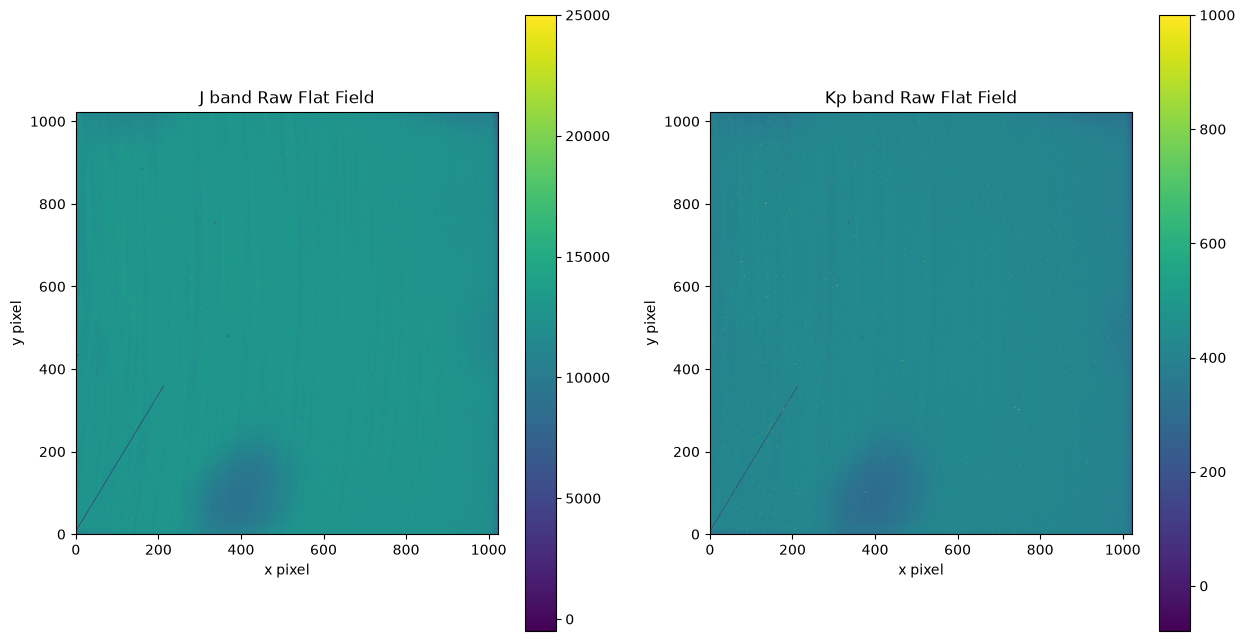

In [4]:
plt.figure('J flat raw', figsize = (15,8))
plt.subplot(121)
plt.title('J band Raw Flat Field')
plt.imshow(J_flat_raw, origin = 'lower', vmax = 25000)
plt.ylabel('y pixel')
plt.xlabel('x pixel')
plt.colorbar()

plt.subplot(122)
plt.title('Kp band Raw Flat Field')
plt.imshow(Kp_flat_raw, origin = 'lower', vmax = 1000)
plt.ylabel('y pixel')
plt.xlabel('x pixel')
plt.colorbar()
plt.show()

## Normalize the Flat Field Images

Use the equation from the introduction and either the numpy (np.) mean or median function to normalize flat field arrays. See how much mean or median impacts your results for this set of observations. **Edit the Code Blow**

In [5]:
J_flat_norm = J_flat_raw/np.mean(J_flat_raw)

Kp_flat_norm = Kp_flat_raw/np.mean(Kp_flat_raw)

## Plot the Normalized Flat Fields Side by Side

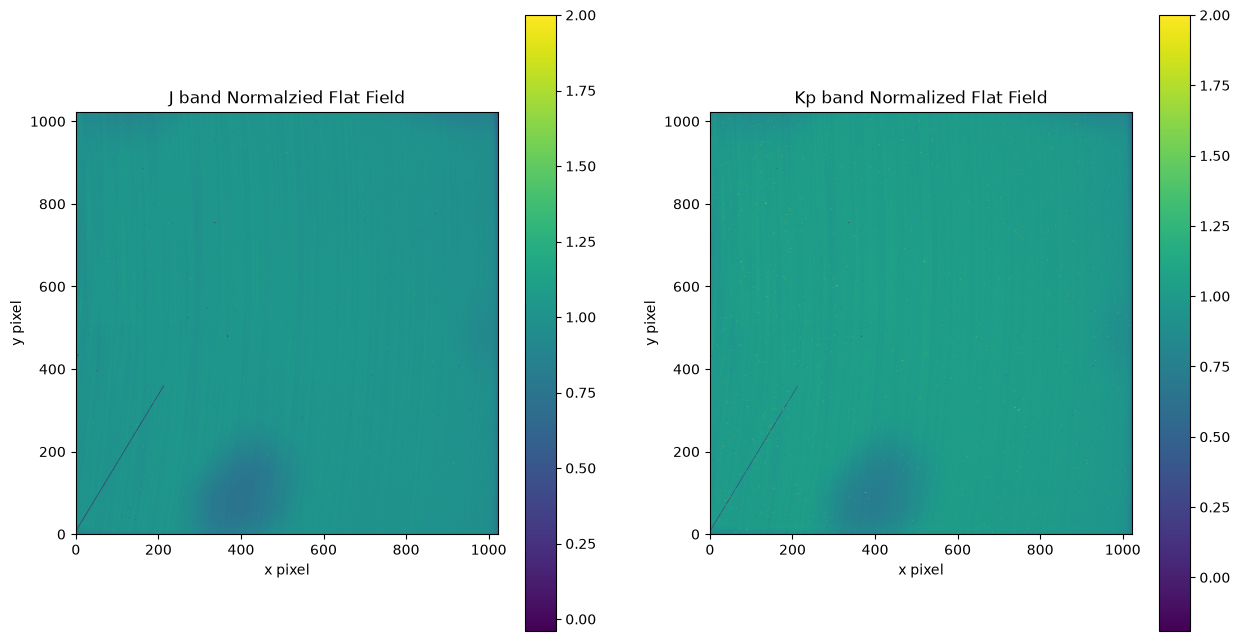

In [6]:
plt.figure('flat norm ', figsize = (15,8))
plt.subplot(121)
plt.title('J band Normalzied Flat Field')
plt.imshow(J_flat_norm, origin = 'lower', vmax = 2)
plt.ylabel('y pixel')
plt.xlabel('x pixel')
plt.colorbar()

plt.subplot(122)
plt.title('Kp band Normalized Flat Field')
plt.imshow(Kp_flat_norm, origin = 'lower', vmax = 2)
plt.ylabel('y pixel')
plt.xlabel('x pixel')
plt.colorbar()
plt.show()

## We'll now call in raw images of Neptune

Look for the directory where image data of npetune is stored. Choose an image pair of Neptune in tbe J and Kp filters where Neptune is on the same location on the detector. You may have to test several files or look at the fits files in DS9.

In [7]:
J_Neptune = fits.getdata('C:/Users/janet/OneDrive/ASTR_302/a3_filters_flat_field/a3_filters_flat_field/neptune_data/J_band/N2.20100821.38944.fits')   #calling in J-band image of Neptune

Kp_Neptune = fits.getdata('C:/Users/janet/OneDrive/ASTR_302/a3_filters_flat_field/a3_filters_flat_field/neptune_data/Kp_band/N2.20100821.38303.fits') #calling in Kp-band image of Neptune

## Then flat field correct Neptune images in each filter

**Edit the Code Below**

In [8]:
J_Neptune_scaled = J_Neptune/J_flat_norm
Kp_Neptune_scaled = Kp_Neptune/Kp_flat_norm

C:\Users\janet\AppData\Local\Temp\ipykernel_39468\4165848479.py:1: RuntimeWarning: invalid value encountered in divide
  J_Neptune_scaled = J_Neptune/J_flat_norm
C:\Users\janet\AppData\Local\Temp\ipykernel_39468\4165848479.py:2: RuntimeWarning: divide by zero encountered in divide
  Kp_Neptune_scaled = Kp_Neptune/Kp_flat_norm
C:\Users\janet\AppData\Local\Temp\ipykernel_39468\4165848479.py:2: RuntimeWarning: invalid value encountered in divide
  Kp_Neptune_scaled = Kp_Neptune/Kp_flat_norm


## Compare raw J-band image to Flat Field Corrected J-band image: Neptune

in the following plots, were are looking at only a subset of the data, by setting the plt.xlim() and plt.ylim() limits. You can comment those lines out the view Neptune on the full detector image

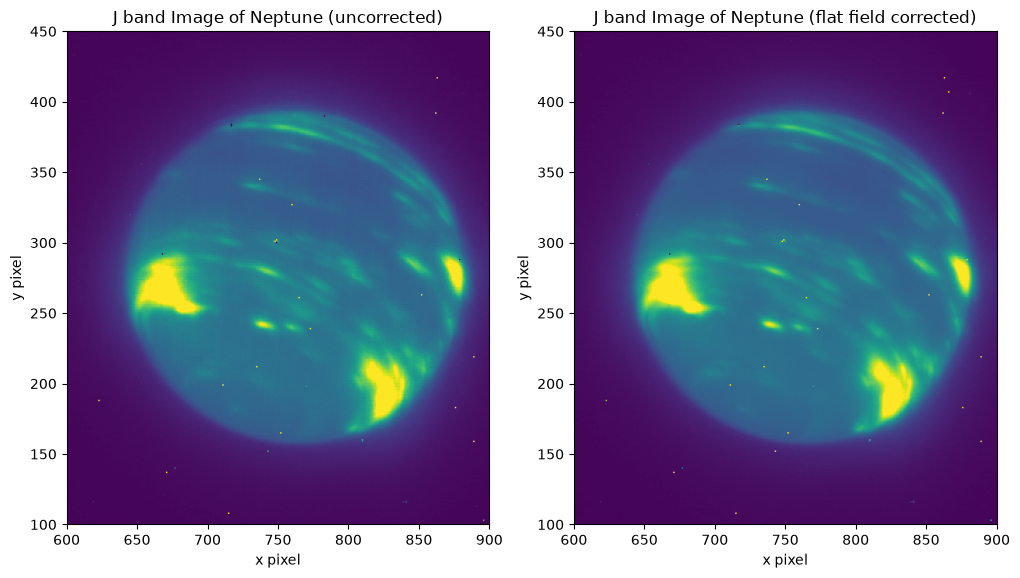

In [19]:
plt.figure('Side by Side J band', figsize = (12,7))
plt.subplot(121)
plt.title('J band Image of Neptune (uncorrected)')
plt.imshow(J_Neptune, origin = 'lower', vmin = 0, vmax = 5000)
#plt.colorbar()
plt.xlim([600,900])
plt.ylim([100,450])
plt.ylabel('y pixel')
plt.xlabel('x pixel')

plt.subplot(122)
plt.title('J band Image of Neptune (flat field corrected)')
plt.imshow(J_Neptune_scaled, origin = 'lower', vmin = 0, vmax = 5000)
#plt.colorbar()
plt.xlim([600,900])
plt.ylim([100,450])
plt.ylabel('y pixel')
plt.xlabel('x pixel')
plt.show()

## Compare raw Kp-band image to Flat Field Corrected Kp-band image: Neptune

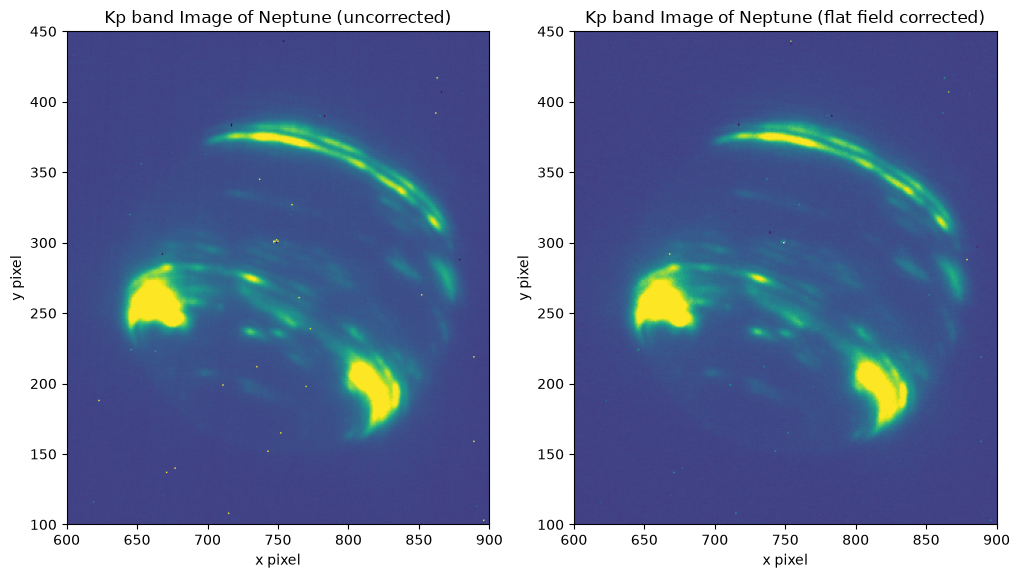

In [21]:
plt.figure('Side by Side Kp', figsize = (12,7))
plt.subplot(121)
plt.title('Kp band Image of Neptune (uncorrected)')
plt.imshow(Kp_Neptune, origin = 'lower', vmin = 0, vmax = 1500)
#plt.colorbar()
plt.xlim([600,900])
plt.ylim([100,450])
plt.ylabel('y pixel')
plt.xlabel('x pixel')

plt.subplot(122)
plt.title('Kp band Image of Neptune (flat field corrected)')
plt.imshow(Kp_Neptune_scaled, origin = 'lower', vmin = 0, vmax = 1500)
#plt.colorbar()
plt.xlim([600,900])
plt.ylim([100,450])
plt.ylabel('y pixel')
plt.xlabel('x pixel')
plt.show()

## Importance of Flat Fielding

Compare the images of Neptune with and without flat field corrections in each bandpass. The "striping" effect on the detector influences the band intensity on Neptune. This also impacts point sources, stars, galaxies, or anything else you want to analyze for your own programs.

## Comparing Neptune in Different Filters

We'll now plot the flat field corrected images of Neptune in J-band and Kp band side by side. What do you notice about the intensity of different atmospheric features. What band is Neptune brighter in? and why do you think that is?

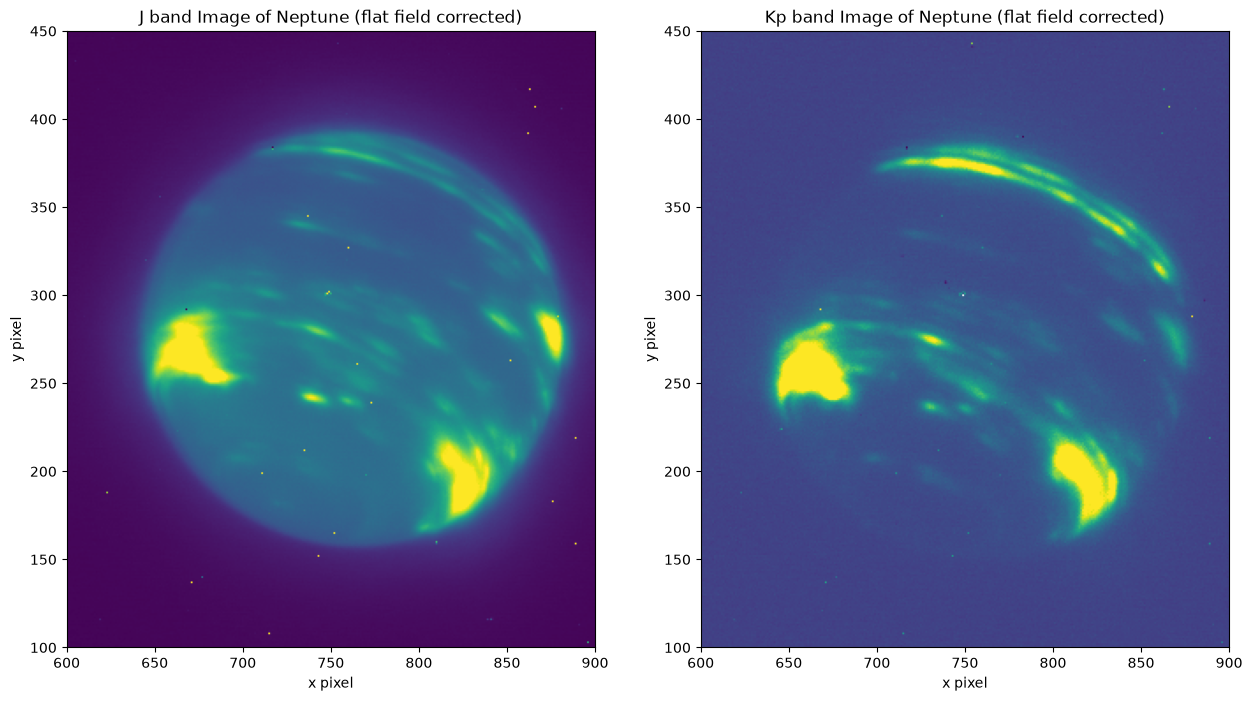

In [23]:
plt.figure('Side by Side J vs Kp', figsize = (15,10))
plt.subplot(121)
plt.title('J band Image of Neptune (flat field corrected)')
plt.imshow(J_Neptune_scaled, origin = 'lower', vmin = 0, vmax = 5000)
#plt.colorbar()
plt.xlim([600,900])
plt.ylim([100,450])
plt.ylabel('y pixel')
plt.xlabel('x pixel')

plt.subplot(122)
plt.title('Kp band Image of Neptune (flat field corrected)')
plt.imshow(Kp_Neptune_scaled, origin = 'lower', vmin = 0, vmax = 1500)
#plt.colorbar()
plt.xlim([600,900])
plt.ylim([100,450])
plt.ylabel('y pixel')
plt.xlabel('x pixel')
plt.show()

# Applying Flat Field Correction to Uranus

First, look in the directory of this assignment to find where the data for Uranus is saved for each bandpass. Open the file with a fits viewer or python to locate where the planet is on the detector. Load an image of Uranus in J and Kprime band with Uranus at the same position on the detector in both bands. The Uranus data was taken on the same night as Neptune so you can apply the same flat field.

## Call in Raw Uranus data

**Edit the Code Below**

In [24]:
J_Uranus = fits.getdata("C:/Users/janet/OneDrive/ASTR_302/a3_filters_flat_field/a3_filters_flat_field/uranus_data/J_band/N2.20100821.39743.fits")

Kp_Uranus = fits.getdata("C:/Users/janet/OneDrive/ASTR_302/a3_filters_flat_field/a3_filters_flat_field/uranus_data/Kp_band/N2.20100821.40291.fits" )

## Then flat field correct Uranus images in each filter

**Edit the Code Below**

In [25]:
J_Uranus_scaled = J_Uranus/J_flat_norm
Kp_Uranus_scaled = Kp_Uranus/Kp_flat_norm

C:\Users\janet\AppData\Local\Temp\ipykernel_39468\1475651209.py:1: RuntimeWarning: divide by zero encountered in divide
  J_Uranus_scaled = J_Uranus/J_flat_norm
C:\Users\janet\AppData\Local\Temp\ipykernel_39468\1475651209.py:2: RuntimeWarning: divide by zero encountered in divide
  Kp_Uranus_scaled = Kp_Uranus/Kp_flat_norm
C:\Users\janet\AppData\Local\Temp\ipykernel_39468\1475651209.py:2: RuntimeWarning: invalid value encountered in divide
  Kp_Uranus_scaled = Kp_Uranus/Kp_flat_norm


## Compare raw J-band image to Flat Field Corrected J-band image: Uranus

**Edit the Code Below**

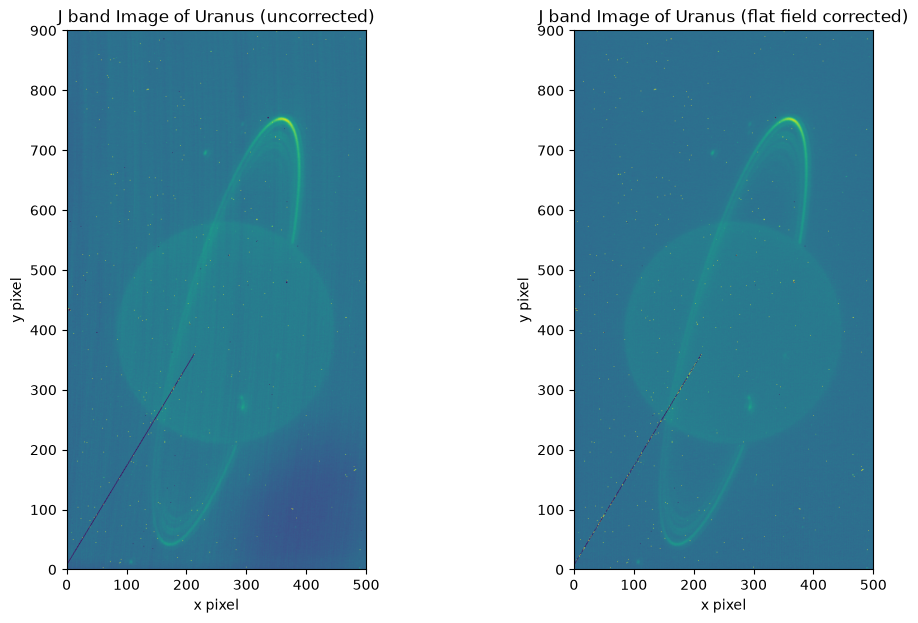

In [36]:
plt.figure('Side by Side J band', figsize = (12,7))
plt.subplot(121)
plt.title('J band Image of Uranus (uncorrected)')
plt.imshow(J_Uranus, origin = 'lower', vmin = 0, vmax = 1500)
#plt.colorbar()
plt.xlim([0,500])
plt.ylim([0,900])
plt.ylabel('y pixel')
plt.xlabel('x pixel')

plt.subplot(122)
plt.title('J band Image of Uranus (flat field corrected)')
plt.imshow(J_Uranus_scaled, origin = 'lower', vmin = 0, vmax = 1500)
#plt.colorbar()
plt.xlim([0,500])
plt.ylim([0,900])
plt.ylabel('y pixel')
plt.xlabel('x pixel')
plt.show()

## Compare raw Kp-band image to Flat Field Corrected Kp-band image: Uranus

**Edit the Code Below**

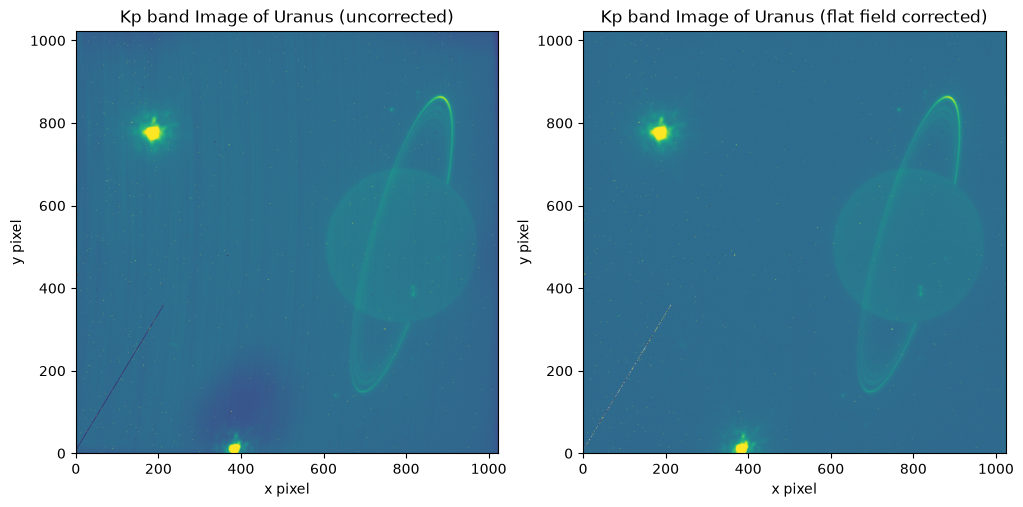

In [32]:
plt.figure('Side by Side Kp', figsize = (12,7))
plt.subplot(121)
plt.title('Kp band Image of Uranus (uncorrected)')
plt.imshow(Kp_Uranus, origin = 'lower', vmin = 0, vmax = 1500)
#plt.colorbar()
#plt.xlim([100,300])
#plt.ylim([700,900])
plt.ylabel('y pixel')
plt.xlabel('x pixel')

plt.subplot(122)
plt.title('Kp band Image of Uranus (flat field corrected)')
plt.imshow(Kp_Uranus_scaled, origin = 'lower', vmin = 0, vmax = 1500)
#plt.colorbar()
#plt.xlim([100,300])
#plt.ylim([700,900])
plt.ylabel('y pixel')
plt.xlabel('x pixel')
plt.show()

## Comparing Neptune vs Uranus

**Create a Plot Comparing Flat Field Corrected imnages of Neptune and Uranus Below**

**Write a response below the following text**

Compare the images of Uranus with and with flat field corrections in each bandpass. Neptune and Uranus are similar in temperature but look very different from one another in the infrared. List at lease three ways these planets appear different from one another. How do they look similar?

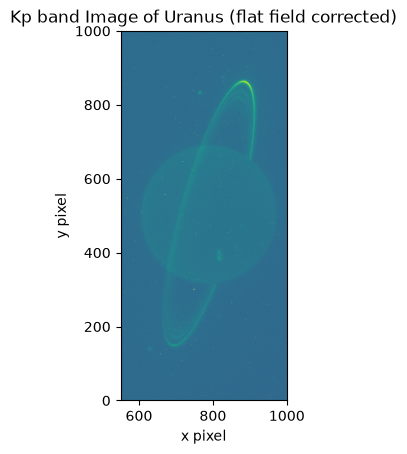

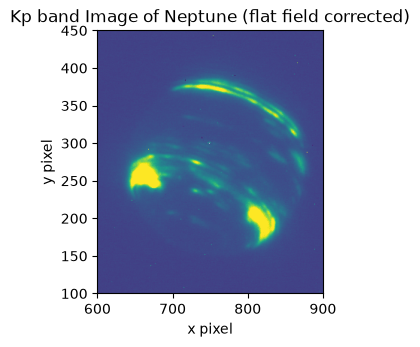

In [50]:
plt.figure("Flat Field Corrected Uranus vs Neptune")
plt.subplot(122)
plt.title('Kp band Image of Uranus (flat field corrected)')
plt.imshow(Kp_Uranus_scaled, origin = 'lower', vmin = 0, vmax = 1500)
#plt.colorbar()
plt.xlim([550,1000])
plt.ylim([0,1000])
plt.ylabel('y pixel')
plt.xlabel('x pixel')
plt.show()

plt.subplot(122)
plt.title('Kp band Image of Neptune (flat field corrected)')
plt.imshow(Kp_Neptune_scaled, origin = 'lower', vmin = 0, vmax = 1500)
#plt.colorbar()
plt.xlim([600,900])
plt.ylim([100,450])
plt.ylabel('y pixel')
plt.xlabel('x pixel')
plt.show()

# Both Uranus and Neptune are visible in the infared, but Uranus' rings are visible while Neptune's are not, Neptune has brighter cloud regions than Uranus,
# while Uranus appears mostly uniform with little variation.

# Comparing the Clouds of Neptune in Different Wavelengths

**Create a Plot Below**

**Write a response below the following text**

Compare zoomed in regions of Neptune's clouds at J and K prime band. Use python subplots with an area no larger than 50 by 50 pixels to understand which clouds appear consistently between both filters. Are there any clouds that appear only at J or K prime band?


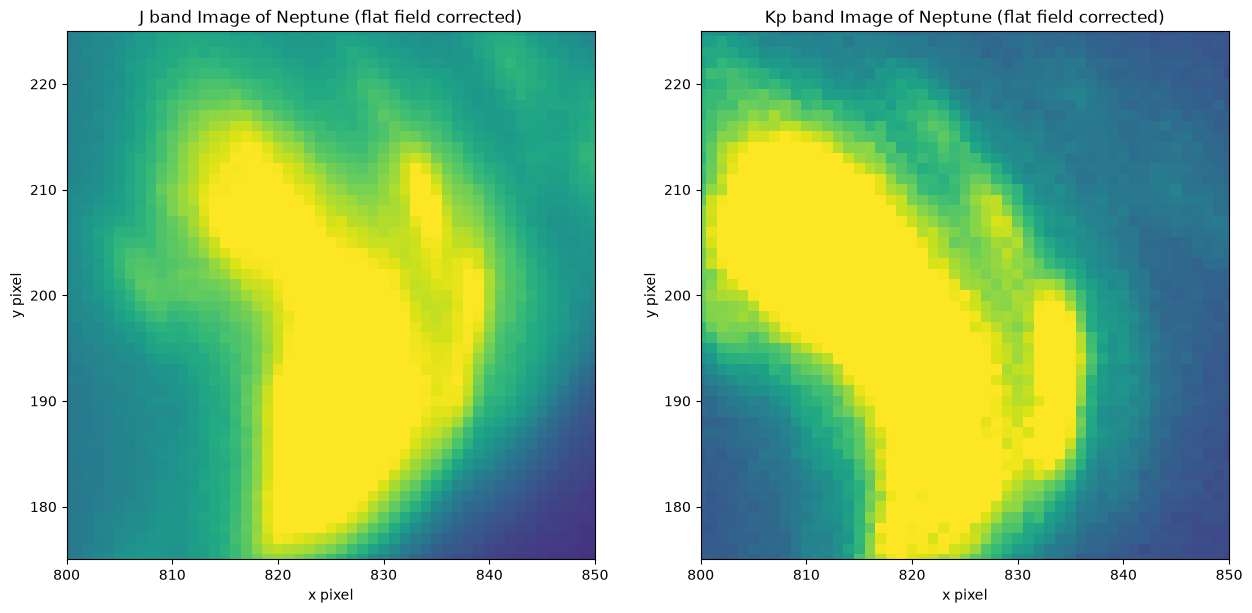

In [52]:
plt.figure('Side by Side J vs Kp', figsize = (15,10))
plt.subplot(121)
plt.title('J band Image of Neptune (flat field corrected)')
plt.imshow(J_Neptune_scaled, origin = 'lower', vmin = 0, vmax = 5000)
#plt.colorbar()
plt.xlim([800,850])
plt.ylim([175,225])
plt.ylabel('y pixel')
plt.xlabel('x pixel')

plt.subplot(122)
plt.title('Kp band Image of Neptune (flat field corrected)')
plt.imshow(Kp_Neptune_scaled, origin = 'lower', vmin = 0, vmax = 1500)
#plt.colorbar()
plt.xlim([800,850])
plt.ylim([175,225])
plt.ylabel('y pixel')
plt.xlabel('x pixel')
plt.show()

#There is a cloud in roughly the same spot but the shape is different, meaning there are aspects of the cloud visible in some wavelengths
# but not others.

# Comparing the Clouds of Uranus in Different Wavelengths

**Create a Plot Below**

**Write a response below the following text**

Compare zoomed in regions of Uranus' clouds at J and K prime band. Use python subplots with an area no larger than 50 by 50 pixels to understand which clouds appear consistently between both filters. Are there any clouds that appear only at J or K prime band?


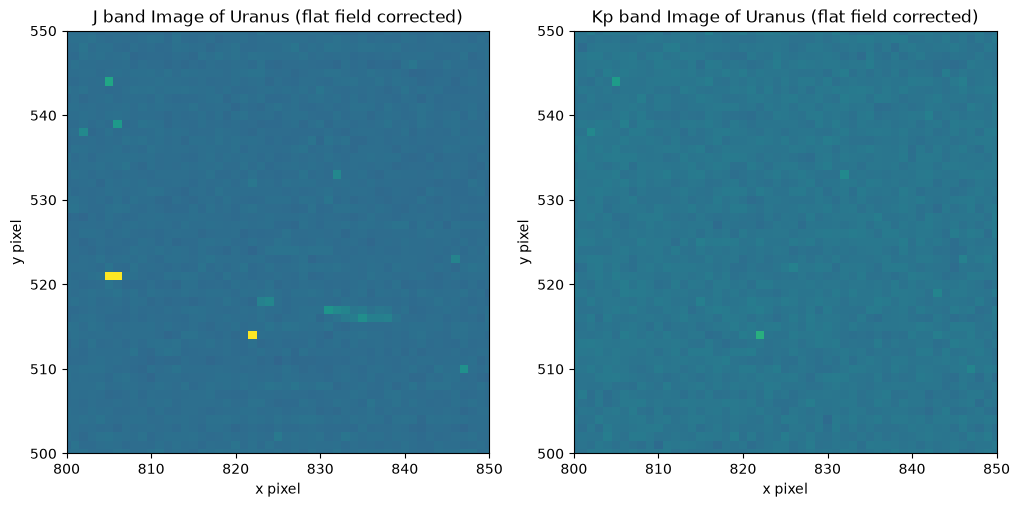

In [72]:
plt.figure("Side by Side Uranus",figsize = (12,7))
plt.subplot(121)
plt.title('J band Image of Uranus (flat field corrected)')
plt.imshow(J_Uranus_scaled, origin = 'lower', vmin = 0, vmax = 1500)
#plt.colorbar()
plt.xlim([800,850])
plt.ylim([500,550])
plt.ylabel('y pixel')
plt.xlabel('x pixel')

plt.subplot(122)
plt.title('Kp band Image of Uranus (flat field corrected)')
plt.imshow(Kp_Uranus_scaled, origin = 'lower', vmin = 0, vmax = 1500)
#plt.colorbar()
plt.xlim([800,850])
plt.ylim([500,550])
plt.ylabel('y pixel')
plt.xlabel('x pixel')
plt.show()
# The cloud variation is mostly the same as in the Kp band, with the exception of some bright spots that is more visible in the J band.

# Comparing the Rings of Uranus in Different Wavelengths

**Create a Plot Below**

Compare zoomed in regions of Uranus' rings at J and K prime band.


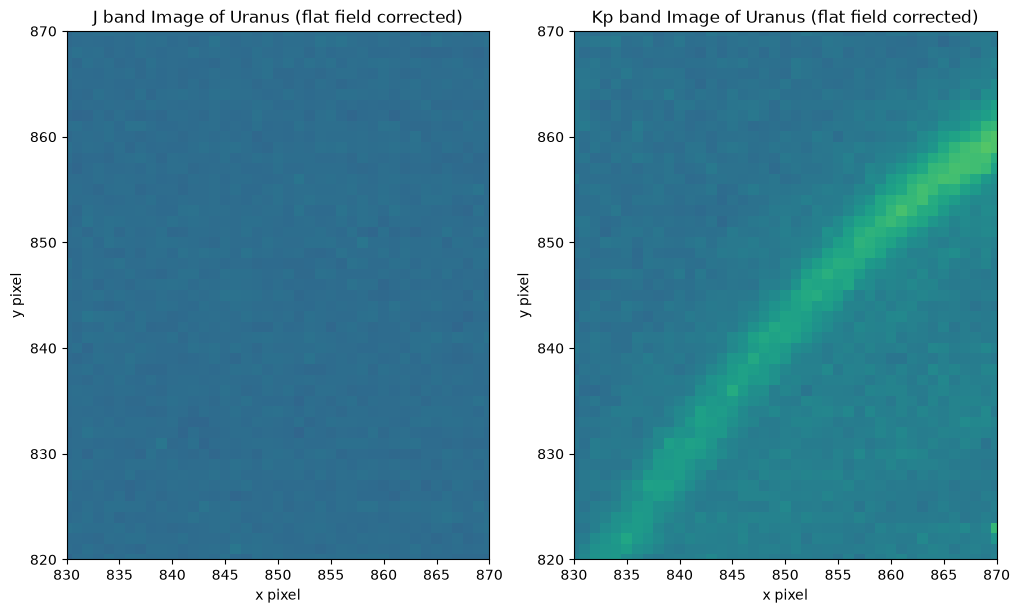

In [71]:
plt.figure("Side by Side Uranus",figsize = (12,7))
plt.subplot(121)
plt.title('J band Image of Uranus (flat field corrected)')
plt.imshow(J_Uranus_scaled, origin = 'lower', vmin = 0, vmax = 1500)
#plt.colorbar()
plt.xlim([830,870])
plt.ylim([820,870])
plt.ylabel('y pixel')
plt.xlabel('x pixel')

plt.subplot(122)
plt.title('Kp band Image of Uranus (flat field corrected)')
plt.imshow(Kp_Uranus_scaled, origin = 'lower', vmin = 0, vmax = 1500)
#plt.colorbar()
plt.xlim([830,870])
plt.ylim([820,870])
plt.ylabel('y pixel')
plt.xlabel('x pixel')
plt.show()

In [73]:
#In the same patch, the ring is not visible in the J band, but it is in the Kp band.